In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

c:\Users\prisc\.conda\envs\eds220-env\Lib\site-packages\nbformat\validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '5a30249f'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
c:\Users\prisc\.conda\envs\eds220-env\Lib\site-packages\nbformat\validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to 'bc54047b'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
c:\Users\prisc\.conda\envs\eds220-env\Lib\site-packages\nbformat\validator.py:434: DuplicateCellId: Non-unique cell id 'b134f8b7-4527-44b2-95f8-2e55880dd4f0' detected. Corrected to '4ce27074'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

https://github.com/pr-scilla/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

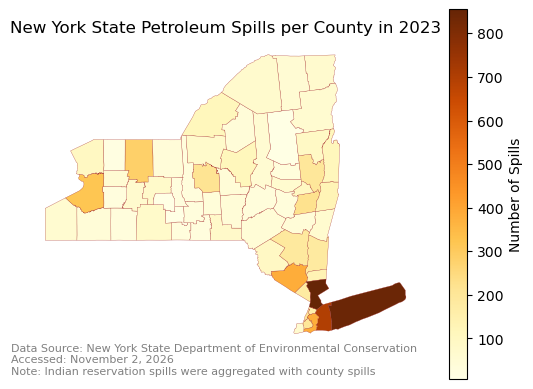

In [ ]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Import NY spills dataset
fp = os.path.join('data', 'Spill_Incidents_20261102.csv')
spills = pd.read_csv(fp)

# Import US counties data using geopandas
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

# Convert spills column names to snake case
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

# Convert values in date columns to datetime data type
date_cols = ['spill_date', 'received_date', 'close_date']
for column in date_cols:
    spills[column] = pd.to_datetime(spills[column])

# Create dataframe of number of petroleum spills per New York county from January to December 2023
spills_per_county = (spills[(spills['spill_date'].dt.year == 2023) & (spills['material_family'] == 'Petroleum')] # Filter to 2023 petroleum spills
                    .groupby('county')['spill_number'].nunique() # Count unique number of spills by county
                    .reset_index()) # Set index to start at 0

# Rename spill_number column to n_spills
spills_per_county = spills_per_county.rename(columns = {'spill_number' : 'n_spills'}) 

# Update St Lawrence value in county column to St. Lawrence
spills_per_county.loc[spills_per_county['county'] == 'St Lawrence', 'county'] = 'St. Lawrence'

# Filter counties to include rows where State Federal Information Processing System code is 36 (New York)
ny_counties = counties[counties['STATEFP'] == '36'] 

# Rename name column in ny_counties to county
ny_counties = ny_counties.rename(columns = {'NAME' : 'county'})

# Join spills_per_county and ny_counties
ny_spills = pd.merge(spills_per_county, ny_counties, how = 'inner', on = 'county')

# Convert ny_spills to geodataframe so geometries are recognized
ny_spills = gpd.GeoDataFrame(ny_spills, geometry = 'geometry', crs = ny_counties.crs)

# Use index value to update Niagara spill count to include 2 Tuscarora Indian Reservation spills in ny_spills
ny_spills.at[31, 'n_spills'] = 97 + 2

# Use index value to update Onondaga spill count to include 1 Onondaga Indian Reservation spill in ny_spills
ny_spills.at[33, 'n_spills'] = 214 + 1

# Initialize empty figure and axes
fig, ax = plt.subplots()

# Remove the axis
ax.axis('off')

# Add ny_spills data to axes
ny_spills.plot(ax=ax,
                column = 'n_spills',
                cmap = 'YlOrBr',
                edgecolor = 'brown',
                linewidth = 0.2,
                legend = True,
                legend_kwds = {'label': "Number of Spills"})

# Add title
ax.set_title('New York State Petroleum Spills per County in 2023')

# Add data source annotation
plt.figtext(0.1, 0.12,
            "Data Source: New York State Department of Environmental Conservation "
            "\nAccessed: November 2, 2026" 
            "\nNote: Indian reservation spills were aggregated with county spills", 
            fontsize = 8,
            color = "grey")

# Display the figure
plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

### NY Spills Data
- The NY spills data is sourced from the [New York State Department of Environmental Conservation](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data). Each record in the dataset contains information on a reported spill of petroleum or other hazardous material in New York state.
- Data were accessed on November 2, 2026.

### US Counties Data
- The US counties data is sourced from the [United States Census Bureau](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html). The shapefiles contain the extent and boundaries of counties and equivalent entities for the United States and United States territories.
- Data were accessed on November 2, 2026.

## 3. Import libraries

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [7]:
# Import NY spills dataset

fp = os.path.join('data', 'Spill_Incidents_20261102.csv')
spills = pd.read_csv(fp)

# Import US counties data using geopandas to recognize geometries

fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

The preliminary exploration steps revealed that the values in the Spill Date, Recieved Date, and Close Date columns are not datetime objects. According to the metadata, the Quantity and Recovered columns should be numbers, however they are currently stored as strings. Only 57,909 records of 574,732 include a zip code (metadata indicated that zip code is not reported for many spills). 121,368 records are missing units for the amount of substance found or spilled (metadata indicated that this field can be left blank if not reported). 12,421 records do not include a Close Date.

The recorded spilled materials in this dataset include Petroleum, Hazardous Material, Oxygenates, and Other. According to the metadata, the County column contains the county location for each spill. Some of the County column values are areas that are not New York counties, including Canada, other states, and reservations. 

Column names are all capitalized and include spaces. It would be easier to work with these columns if they were updated to snake case before proceeding.

In [8]:
#a. Check the dataframe's head

spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [9]:
# Display column names, number of non-null values in each column, and data type for each column

spills.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574732 entries, 0 to 574731
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Spill Number           574732 non-null  int64 
 1   Program Facility Name  574726 non-null  object
 2   Street 1               574598 non-null  object
 3   Street 2               44735 non-null   object
 4   Locality               573581 non-null  object
 5   County                 574732 non-null  object
 6   ZIP Code               57909 non-null   object
 7   SWIS Code              574732 non-null  int64 
 8   DEC Region             574732 non-null  int64 
 9   Spill Date             574581 non-null  object
 10  Received Date          574229 non-null  object
 11  Contributing Factor    574732 non-null  object
 12  Waterbody              47992 non-null   object
 13  Source                 574732 non-null  object
 14  Close Date             562311 non-null  object
 15  

In [10]:
#b. Check the data types of the columns

spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [11]:
#c. Check the unique values in the `material_family` column

spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [12]:
#d. Check the unique values in the `county` column

spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [13]:
# Convert column names to snake case
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

# Print column names to verify updates
print(spills.columns)

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [14]:
# Create list of date columns from spills dataframe
date_cols = ['spill_date', 'received_date', 'close_date']

# Convert values in date columns to datetime data type and verify
for column in date_cols:
    spills[column] = pd.to_datetime(spills[column])
    print(f"{column} column values are {spills[column].dtype}")

spill_date column values are datetime64[ns]
received_date column values are datetime64[ns]
close_date column values are datetime64[ns]


In [15]:
# Create list of columns to update to numbers
number_cols = ['quantity', 'recovered']

# Convert values in number columns to numbers and verify
for column in number_cols:
    spills[column] = spills[column].str.replace(',','') # Remove any commas from values
    spills[column] = pd.to_numeric(spills[column])
    print(f"{column} column values are {spills[column].dtype}")

quantity column values are float64
recovered column values are float64


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [16]:
# Filter spills dataframe to include only petroleum spill records that took place in 2023 

petr_23 = spills[(spills['spill_date'].dt.year == 2023) & (spills['material_family'] == 'Petroleum')]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [17]:

print(# Access minimum month value from spill_date and confirm it is January
 f"The petr_23 dataframe only contains data from {np.where(petr_23['spill_date'].dt.month.min() == 1, 'January', 'not January')}"
 # Access the maximum month value from spill_date and confirm it is December
 f" to {np.where(petr_23['spill_date'].dt.month.max() == 12, 'December', 'not December')}"
 # Access the unique year value from spill_date
 f" {petr_23['spill_date'].dt.year.unique()}")

The petr_23 dataframe only contains data from January to December [2023]


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [18]:
for value in petr_23['material_family']:
    assert value == 'Petroleum' # Assert that Petroleum is the only value in the material_family column

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

There are less unique spill numbers in this dataset than there are rows, which indicates that some of the spill numbers are repeated. After checking records where spill_number is duplicated, it appears that some petroleum spills included multiple different types of petroleum materials. Each unique petroleum material (material_name) gets recorded in a separate row for spills where more than one type of petroleum material was spilled.

In [19]:
print(f"The petr_23 dataframe has {len(petr_23):,} rows and contains {petr_23['spill_number'].nunique():,} unique spill records.")

The petr_23 dataframe has 8,468 rows and contains 8,228 unique spill records.


In [20]:
# Create dataframe of rows where spill_number is duplicated
repeat_spill_number = petr_23[petr_23.duplicated(subset = ['spill_number'], keep = False)]

# Look at last 10 values of dataframe
repeat_spill_number.tail(10)

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
562497,2303761,WEST SENECA TRANSFER STATION,500 MINERAL SPRINGS RD,NaN,WEST SENECA,Erie,NaN,1568,9,2023-08-02,2023-08-02,Other,NaN,Commercial Vehicle,2024-02-28,hydraulic oil,Petroleum,60.0,Gallons,0.0
564772,2304802,WETLANDS,EAST MAHONEY ROAD AND KEENAN ROAD,NaN,BRASHER FALLS,St Lawrence,13613,4520,6,2023-09-05,2023-09-05,Vandalism,NaN,Commercial/Industrial,2023-09-08,motor oil,Petroleum,0.0,NaN,0.0
564788,2304802,WETLANDS,EAST MAHONEY ROAD AND KEENAN ROAD,NaN,BRASHER FALLS,St Lawrence,13613,4520,6,2023-09-05,2023-09-05,Vandalism,NaN,Commercial/Industrial,2023-09-08,gasoline,Petroleum,0.0,NaN,0.0
570040,2308488,WOODVILLE DIESEL,8053 NYS ROUTE 289,NaN,BELLEVILLE,Jefferson,13617,2334,6,2023-12-15,2024-01-12,Deliberate,NaN,Commercial/Industrial,2024-11-08,engine oil,Petroleum,10.0,Gallons,0.0
570041,2308488,WOODVILLE DIESEL,8053 NYS ROUTE 289,NaN,BELLEVILLE,Jefferson,13617,2334,6,2023-12-15,2024-01-12,Deliberate,NaN,Commercial/Industrial,2024-11-08,transmission fluid,Petroleum,10.0,Gallons,0.0
570648,2302927,WVDP,10282 ROCK SPRINGS RD,NaN,WEST VALLEY,Cattaraugus,NaN,522,9,2023-07-06,2023-07-06,Equipment Failure,NaN,"Institutional, Educational, Gov., Other",2023-07-06,diesel,Petroleum,0.0,Gallons,0.0
570651,2302927,WVDP,10282 ROCK SPRINGS RD,NaN,WEST VALLEY,Cattaraugus,NaN,522,9,2023-07-06,2023-07-06,Equipment Failure,NaN,"Institutional, Educational, Gov., Other",2023-07-06,motor oil,Petroleum,0.0,Gallons,0.0
570659,2302927,WVDP,10282 ROCK SPRINGS RD,NaN,WEST VALLEY,Cattaraugus,NaN,522,9,2023-07-06,2023-07-06,Equipment Failure,NaN,"Institutional, Educational, Gov., Other",2023-07-06,hydraulic oil,Petroleum,0.0,Gallons,0.0
572548,2302747,YATES COUNTY HIGHWAY,939 NY-14A,"~ 42.718577, -77.065120",PENN YAN,Yates,14527,6222,8,2023-07-06,2023-07-06,Equipment Failure,NaN,Commercial/Industrial,2025-11-14,gasoline,Petroleum,0.0,NaN,0.0
572549,2302747,YATES COUNTY HIGHWAY,939 NY-14A,"~ 42.718577, -77.065120",PENN YAN,Yates,14527,6222,8,2023-07-06,2023-07-06,Equipment Failure,NaN,Commercial/Industrial,2025-11-14,diesel,Petroleum,0.0,NaN,0.0


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [21]:
spills_per_county = (spills[(spills['spill_date'].dt.year == 2023) & (spills['material_family'] == 'Petroleum')] # Filter to 2023 petroleum spills
                    .groupby('county')['spill_number'].nunique() # Count unique number of spills by county
                    .reset_index()) # Set index to start at 0
spills_per_county = spills_per_county.rename(columns = {'spill_number' : 'n_spills'}) # Rename spill_number column to n_spills

In [22]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

The geometries in the counties dataframe are polygons. Based on the extent of the plot and the county names (NAME column values) shown in the first five rows of the dataframe, the counties data contains information for areas throughout the United States and United States territories. The coordinate reference system of the counties dataframe geometries is EPSG:4269. Most values in the dataframe are stored as strings except for values in the ALAND (int64), AWATER(int64), and geometry (geometry) columns.

In [23]:
# a Check first five rows of the counties dataframe

counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [24]:
# b Check column data types
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [25]:
# c Check the CRS 
print(f"The CRS of the counties geo-dataframe is {counties.crs}.")

The CRS of the counties geo-dataframe is EPSG:4269.


<Axes: >

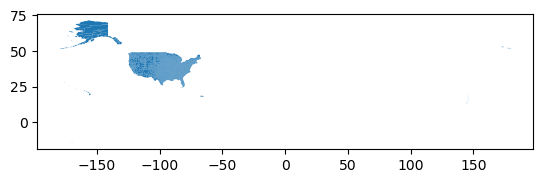

In [26]:
# d Plot the counties dataframe
counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [27]:
# Rename name column to county_name
counties = counties.rename(columns = {'NAME' : 'county_name'})

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

<Axes: >

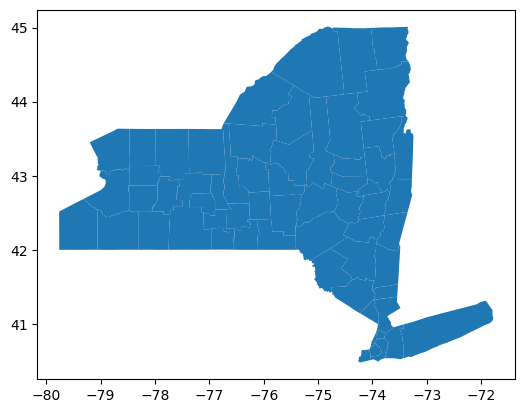

In [28]:
# Filter to include rows where State Federal Information Processing System code is 36 (New York)
ny_counties = counties[counties['STATEFP'] == '36'] 

# Plot ny_counties
ny_counties.plot()


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [29]:
# Print unique county names from ny_counties
print(ny_counties['county_name'].unique())

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [30]:
# Print unique county names from spills_per_county
print(spills_per_county['county'].unique())

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [ ]:
# Check which county names are in spills_per_county but not ny_counties
diff_names_spills = np.setdiff1d(spills_per_county['county'].unique(), ny_counties['county_name'].unique())
diff_names_spills


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [32]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [ ]:
# Check which county names are in ny_counties but not in spills_per_county
diff_names_ny = np.setdiff1d(ny_counties['county_name'].unique(), spills_per_county['county'].unique())
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [34]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [35]:
# e. Print number of spills at Tuscarora Indian Reservation and Onondaga Indian Reservation
print(spills_per_county.loc[spills_per_county['county'].isin(['Tuscarora Indian Reservation', 'Onondaga Indian Reservation'])])

                          county  n_spills
35   Onondaga Indian Reservation         1
58  Tuscarora Indian Reservation         2


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [36]:
# Update St Lawrence value in county column to St. Lawrence
spills_per_county.loc[spills_per_county['county'] == 'St Lawrence', 'county'] = 'St. Lawrence'

# Check if updated St. Lawrence is in the county column
assert spills_per_county['county'].isin(['St. Lawrence']).any()

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [37]:
# a Update ny_counties county_name column to county to match spills_per_county

ny_counties = ny_counties.rename(columns = {'county_name' : 'county'})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [ ]:
# Join spills_per_county and ny_counties
ny_spills = pd.merge(spills_per_county, ny_counties, how = 'inner', on = 'county')

# Convert ny_spills to geodataframe so geometries are recognized
ny_spills = gpd.GeoDataFrame(ny_spills, geometry = 'geometry', crs = ny_counties.crs)

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [39]:
# Check which county records are in spills_per_county and not in ny_counties
print(f"The counties in spills_per_county that were dropped in the inner join are: "
      f"{np.setdiff1d(spills_per_county['county'].unique(), ny_counties['county'].unique())}")

The counties in spills_per_county that were dropped in the inner join are: ['New Jersey - Region 2' 'Onondaga Indian Reservation'
 'Pennsylvania - Region 3' 'Tuscarora Indian Reservation']


In [40]:
# Make list of counties that are in spills_per_county and not in ny_counties
county_records = ['New Jersey - Region 2', 'Onondaga Indian Reservation', 'Pennsylvania - Region 3', 'Tuscarora Indian Reservation']

# Print county names and count of spills
print(spills_per_county.loc[spills_per_county['county'].isin(county_records)])

                          county  n_spills
30         New Jersey - Region 2         7
35   Onondaga Indian Reservation         1
41       Pennsylvania - Region 3         1
58  Tuscarora Indian Reservation         2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

Dropping the spills from New Jersey - Region 2 and Pennsylvania - Region 3 will remove information from spills that originated outside of New York state, which is acceptable for the scope of this analysis. 

Because Indian Reservations are separate from counties, they are omitted from the analysis because they are not accounted for in ny_counties. Omitting the Onondaga Indian Reservation and Tuscarora Indian Reservation records erases spill information from spills that occurred on tribal lands, even though they occurred within New York state.

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [41]:

# Print count of spills in Niagara county and Onondaga county from ny_spills
print(ny_spills.loc[ny_spills['county'].isin(['Niagara', 'Onondaga']), ['county','n_spills']])
# Print count of spills in Tuscarora Indian Reservation and Onondaga Indian Reservation from spills_per_county
print(spills_per_county.loc[spills_per_county['county'].isin(['Tuscarora Indian Reservation', 'Onondaga Indian Reservation'])])


      county  n_spills
31   Niagara        97
33  Onondaga       214
                          county  n_spills
35   Onondaga Indian Reservation         1
58  Tuscarora Indian Reservation         2


In [42]:
# Use index value to update Niagara spill count to include Tuscarora Indian Reservation spills in ny_spills
ny_spills.at[31, 'n_spills'] = 97 + 2

# Verify dataframe was updated
assert ny_spills.loc[31, 'n_spills'] == (97 + 2)

In [43]:
# Use index value to update Onondaga spill count to include Onondaga Indian Reservation spills in ny_spills
ny_spills.at[33, 'n_spills'] = 214 + 1

# Verify dataframe was updated
assert ny_spills.loc[33, 'n_spills'] == (214 + 1)

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



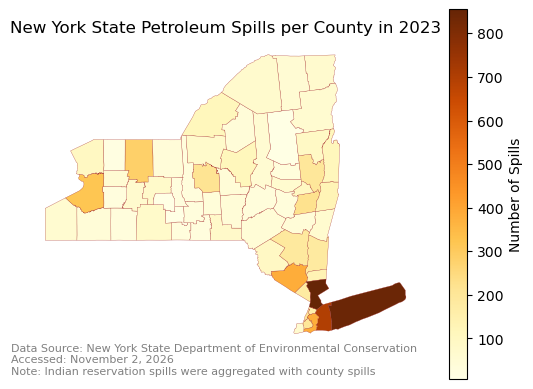

In [44]:
# Initialize empty figure and axes

fig, ax = plt.subplots()

# Remove the axis
ax.axis('off')

# Add ny_spills data to axes
ny_spills.plot(ax=ax,
                column = 'n_spills',
                cmap = 'YlOrBr',
                edgecolor = 'brown',
                linewidth = 0.2,
                legend = True,
                legend_kwds = {'label': "Number of Spills"})

# Add title
ax.set_title('New York State Petroleum Spills per County in 2023')

# Add data source annotation
plt.figtext(0.1, 0.12,
            "Data Source: New York State Department of Environmental Conservation "
            "\nAccessed: November 2, 2026" 
            "\nNote: Indian reservation spills were aggregated with county spills", 
            fontsize = 8,
            color = "grey")

# Display the figure
plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.


Creating the map highlighted the importance of exploring each dataset and reading metadata before proceeding with analysis. Exploration of the datasets revealed that several data cleaning, filtering, and verification steps were needed to ensure that the resulting map included all spills of interest (petroleum spills that occurred in New York counties in 2023). Cleaning and filtering also required me to make decisions on how to handle certain records, which was important to document in markdown cells and code comments for future reference.  

The five New York counties with the greatest number of reported petroleum spills in 2023 were:

| County | Spill Number |
| -------- | -------- |
| Westchester  | 855   |
| Suffolk  | 845   |
| Nassau  | 698   |
| Orange  | 382   |
| Queens  | 380   |

The five New York counties with the lowest number of reported petroleum spills in 2023 were:

| County | Spill Number |
| -------- | -------- |
| Wyoming  | 27 |
| Orleans  | 19   |
| Schuyler  | 13   |
| Hamilton  | 12   |
| Yates  | 7   |


Spills that were reported from the Tuscarora and Onondaga Indian Reservations were added to the spill counts for Niagara county and Onondaga county, respectively. While this accounted for the general region within the state where these spills occurred, it erases the geographical context that tied these records to indian reservations. This goes against the CARE Principes for Indigenous Data Governance, particularly (C) Collective Benefit and (A) Authority to Control. Erasing the association of these spills with indian reservations deprives the indigenous peoples in these areas from the option to support local decision-making and erases their representation on the resulting map.

In [45]:
# Find the five counties with greatest number of spills
ny_spills.groupby('county')['n_spills'].sum().sort_values(ascending = False).head(5)

county
Westchester    855
Suffolk        845
Nassau         698
Orange         382
Queens         380
Name: n_spills, dtype: int64

In [46]:
# Find the five counties with the least number of spills
ny_spills.groupby('county')['n_spills'].sum().sort_values(ascending = False).tail(5)

county
Wyoming     27
Orleans     19
Schuyler    13
Hamilton    12
Yates        7
Name: n_spills, dtype: int64

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.